# Map flux
## Make the same maps as the one presented in https://arxiv.org/pdf/2104.06855.pdf

### Import modules

In [2]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import Colormap
import pandas as pd
from scipy.interpolate import interp1d

/home/tomas/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


### User parameters

In [3]:
incl = 48 * np.pi / 180.0
Nx = 32
f_Ny = 0.15 # Nyquist frequency (< 0.6)
#co = sqrt(8.d0*log(2.d0))       ! difference between sigma and theta!, theta = sigma*co

### Define some constants

In [4]:
h = 6.6260755e-27
m_e = 9.10938e-28
c = 2.99792458e10
e = 4.8032068e-10
kpc = 3.0856e21  #Kpc a cm
distance = 3.8e3  #Distancia al objeto en kpc
convert = 206265e3/(distance*kpc) # image to angular size (mas)
# flux = 1.e26*(h/eV)/(4.0*np.pi*(distance*kpc)**2) # L[erg/s/erg] -> F[mJy]

### Define some useful functions

In [5]:
def safe_log(x):
    return np.where(x > 0, np.log(x), -300)

#### Funcion de potencia

In [6]:
def get_j_alpha(nu, delta, filename='./../Code/Em_Abs.dat'):
    # Read the data from the file
    data = pd.read_csv(filename, delim_whitespace=True, header=None, names=["energy", "emisivity", "absorption", "z_value"])
    
    # Find the energy associated with the given frequency nu
    energy_nu = h * nu * 1e9  # Convert frequency to energy
    
    # Filter the data for each z_value
    filtered_data = []
    for z in data["z_value"].unique():
        z_data = data[data["z_value"] == z]
        closest_index = (np.abs(z_data["energy"] - energy_nu/delta[z-1])).idxmin()
        filtered_data.append(z_data.loc[closest_index, ["energy", "emisivity", "absorption"]])

    # Combine the filtered data into a DataFrame
    filtered_data = pd.DataFrame(filtered_data)
    return filtered_data['emisivity'], filtered_data['absorption']

In [7]:
# j, alpha= get_j_alpha(45.0)

# j = j.to_numpy()
# for i in values:
#     print(j[i-1], i)


In [8]:
def get_z_rz(filename='./../Code/quant_FF.dat',filename2='./../Code/quant_FF_norm.dat'):
    """
    Load and return specific columns from the given file.

    Parameters:
        filename (str): Path to the file containing the data.

    Returns:
        tuple: Arrays of z, B, r_out, r_in, and delta_obs values.
    """
    return np.loadtxt(filename, usecols=(0, 1, 2, 3, 5), unpack=True)

In [9]:
def crossed_length(x, R_in, R_out):
        if abs(x) < abs(R_out) and abs(x) > abs(R_in):
                l = 2.0 * np.sqrt(R_out**2 - x**2)
        elif abs(x) <= abs(R_in):
                l = 2.0 * (np.sqrt(R_out**2 - x**2) - np.sqrt(abs(R_in**2 - x**2)))
        else:
                l = 0.0
        return l

In [ ]:
#Esta interpola las funciones de z
def Intensity_import_interp(x_value, nu, z_value):
    '''
    Function that returns the intensity for a given frequency at a given range of z, determined by the length of the input array.
    The function uses the values of absoption and emissivity imported from the function get_j_alpha that are closest to the specified energy
    (given by nu) to calculate the intensity based on the input parameters.
    
    This function interpolates for any given value of z'''

    # Retrieve data
    if not hasattr(Intensity_import_interp, "_cached_data"):
        z, B, r_out, r_in, delta_obs = get_z_rz()
        delta_obs = np.sqrt(delta_obs)
        j, alpha = get_j_alpha(nu, delta_obs)
        Intensity_import_interp._cached_data = (z, B, r_out, r_in, delta_obs, j, alpha)
    else:
        z, B, r_out, r_in, delta_obs, j, alpha = Intensity_import_interp._cached_data
    j=j.to_numpy()
    alpha=alpha.to_numpy()
    # Precompute constants

    # Interpolations
    I_z_values = [delta_obs[idx]**3 * j[idx] / alpha[idx] for idx in range(len(z))]
    term_exp_values = [alpha[idx] / delta_obs[idx] for idx in range(len(z))]
    # Remove NaN values from I_z_values and term_exp_values
    valid_indices = ~np.isnan(I_z_values) & ~np.isnan(term_exp_values)
    I_z_values = np.array(I_z_values)[valid_indices]
    term_exp_values = np.array(term_exp_values)[valid_indices]
    z2 = np.array(z)[valid_indices]

    I_z = interp1d(safe_log(z2), safe_log(I_z_values), bounds_error=False, fill_value='extrapolate')
    term_exp = interp1d(safe_log(z2), safe_log(term_exp_values), bounds_error=False, fill_value='extrapolate')
    r_out_interp = interp1d(safe_log(z), safe_log(r_out), bounds_error=False, fill_value='extrapolate')
    r_in_interp = interp1d(safe_log(z), safe_log(r_in), bounds_error=False, fill_value='extrapolate')

    # Compute intensity
    intensity_result = np.zeros(len(x_value))
    for j, x in enumerate(x_value):
        tau = crossed_length(x, np.exp(r_in_interp(safe_log(z_value))), np.exp(r_out_interp(safe_log(z_value)))) * np.exp(term_exp(safe_log(z_value))) / np.sin(incl)
        intensity_result[j] = np.exp(I_z(safe_log(z_value))) * (-np.expm1(-tau))
    

    return intensity_result
z, _, r_out, _, _ = get_z_rz()
z = np.linspace(z.min(), z.max(), 200)
x = np.linspace(-r_out.max(), r_out.max(), 200)
print(x)
# Create a meshgrid for plotting
X_m, Z_m = np.meshgrid(x, z)
I = np.zeros((len(z), len(x)))
for i, z_value in enumerate(z):
    I[i]=Intensity_import_interp(x, 45.0, z_value)




[-4.10046559e+15 -4.08403086e+15 -4.06759613e+15 -4.05116139e+15
 -4.03472666e+15 -4.01829193e+15 -4.00185720e+15 -3.98542247e+15
 -3.96898774e+15 -3.95255300e+15 -3.93611827e+15 -3.91968354e+15
 -3.90324881e+15 -3.88681408e+15 -3.87037934e+15 -3.85394461e+15
 -3.83750988e+15 -3.82107515e+15 -3.80464042e+15 -3.78820569e+15
 -3.77177095e+15 -3.75533622e+15 -3.73890149e+15 -3.72246676e+15
 -3.70603203e+15 -3.68959729e+15 -3.67316256e+15 -3.65672783e+15
 -3.64029310e+15 -3.62385837e+15 -3.60742364e+15 -3.59098890e+15
 -3.57455417e+15 -3.55811944e+15 -3.54168471e+15 -3.52524998e+15
 -3.50881524e+15 -3.49238051e+15 -3.47594578e+15 -3.45951105e+15
 -3.44307632e+15 -3.42664159e+15 -3.41020685e+15 -3.39377212e+15
 -3.37733739e+15 -3.36090266e+15 -3.34446793e+15 -3.32803319e+15
 -3.31159846e+15 -3.29516373e+15 -3.27872900e+15 -3.26229427e+15
 -3.24585954e+15 -3.22942480e+15 -3.21299007e+15 -3.19655534e+15
 -3.18012061e+15 -3.16368588e+15 -3.14725114e+15 -3.13081641e+15
 -3.11438168e+15 -3.09794

/tmp/ipykernel_41497/3843225759.py:3: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data = pd.read_csv(filename, delim_whitespace=True, header=None, names=["energy", "emisivity", "absorption", "z_value"])
/tmp/ipykernel_41497/374573316.py:23: RuntimeWarning: invalid value encountered in scalar divide
  I_z_values = [delta_obs[idx]**3 * j[idx] / alpha[idx] for idx in range(len(z))]


In [16]:
if hasattr(Intensity_import_interp, "_cached_data"):
    del Intensity_import_interp._cached_data

/tmp/ipykernel_41497/3843225759.py:3: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data = pd.read_csv(filename, delim_whitespace=True, header=None, names=["energy", "emisivity", "absorption", "z_value"])


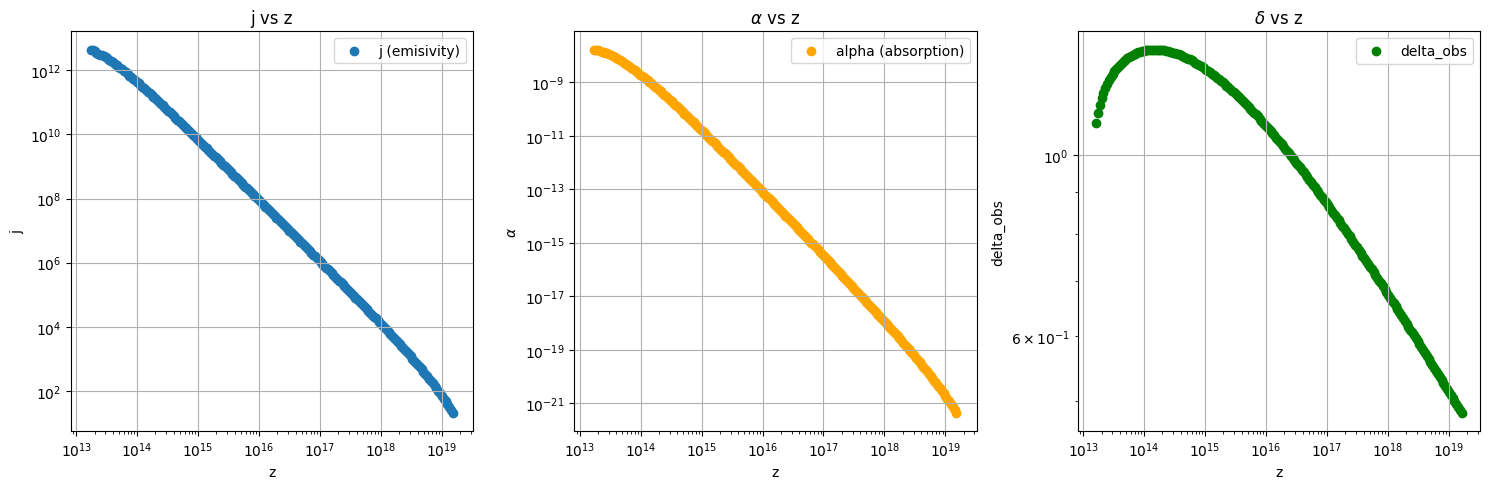

In [17]:
z, B, r_out, r_in, delta_obs = get_z_rz()
delta_obs = np.sqrt(delta_obs)
j, alpha = get_j_alpha(45.0, delta_obs)

plt.figure(figsize=(15, 5))

# Plot j vs z
plt.subplot(1, 3, 1)
plt.scatter(z, j, label='j (emisivity)')
plt.xlabel('z')
plt.ylabel('j')
plt.xscale('log')
plt.yscale('log')
plt.title('j vs z')
plt.grid()
plt.legend()

# Plot alpha vs z
plt.subplot(1, 3, 2)
plt.scatter(z, alpha, label='alpha (absorption)', color='orange')
plt.xlabel('z')
plt.ylabel(r'$\alpha$')
plt.xscale('log')
plt.yscale('log')
plt.title(r'$\alpha$ vs z')
plt.grid()
plt.legend()

# Plot delta_obs vs z
plt.subplot(1, 3, 3)
plt.scatter(z, delta_obs, label='delta_obs', color='green')
plt.xlabel('z')
plt.ylabel('delta_obs')
plt.xscale('log')
plt.yscale('log')
plt.title(r'$\delta$ vs z')
plt.grid()
plt.legend()

plt.tight_layout()
plt.show()

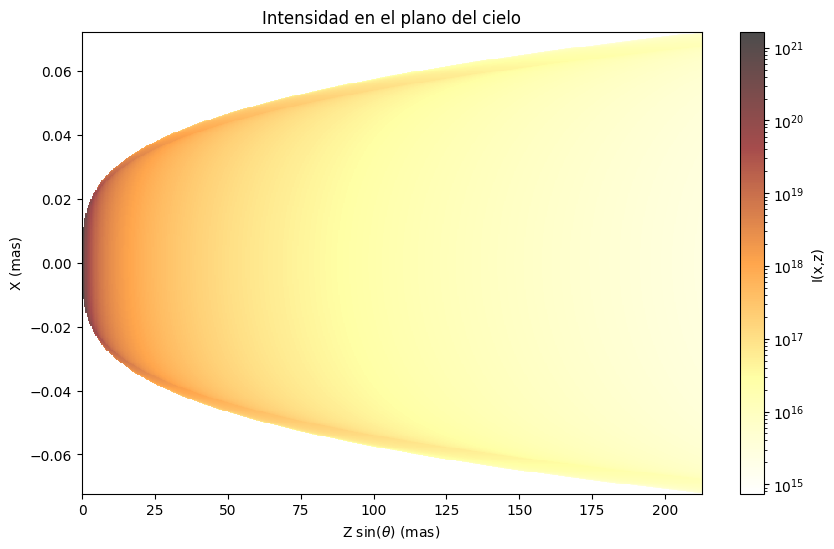

In [18]:
# Plotting

palette = plt.cm.afmhot_r
plt.figure(figsize=(10, 6))
norm = matplotlib.colors.LogNorm(vmin=I[I > 0].min(), vmax=I.max())
plt.pcolormesh(Z_m * np.sin(incl) * convert, X_m * convert, I, cmap=palette, norm=norm, alpha=0.7)
#plt.pcolormesh(Z_m * np.sin(incl) * convert, X_m * convert, I, cmap=palette, alpha=0.7)
plt.colorbar(label='I(x,z)')
plt.xlabel(r'Z $\sin(\theta)$ (mas)')
plt.ylabel('X (mas)')
plt.title(r'Intensidad en el plano del cielo')
plt.show()